   
WarmUp
=======

Trend-Seasonal
=======

Differencing
===========

Exponential-smoothing
===================


**Times series course**  
IMT Mines ALES  
2IA



In [6]:
import pandas as pd
import datetime as dt
import matplotlib.pyplot as plt
import numpy as np
plt.rcParams['figure.figsize'] = [15, 5]


In [7]:
df = pd.read_csv('data/shampoo_sales.csv', parse_dates=True, header=0)
df.Month = df.Month.apply(lambda x: '199' +x )
df.index = pd.to_datetime(df.Month, format='%Y-%m') + pd.offsets.DateOffset(years=4)
df = df.drop(['Month'], axis=1)
df.head()


,Sales
Month,
1995-01-01,266.0
1995-02-01,145.9
1995-03-01,183.1
1995-04-01,119.3
1995-05-01,180.3


In [8]:
data = df.Sales.values.tolist()
print(data[:10])



[266.0, 145.9, 183.1, 119.3, 180.3, 168.5, 231.8, 224.5, 192.8, 122.9]


## Simple exponential smoothing

Implement the simple exponential smoothing from its update equation. Please write a recursive function `simple_es(series, alpha)`.  

Forecast the last value of the time series (as it were unknown).    
Plot it on a graph.

December 1997: forecast = 491.51, actual = 646.90


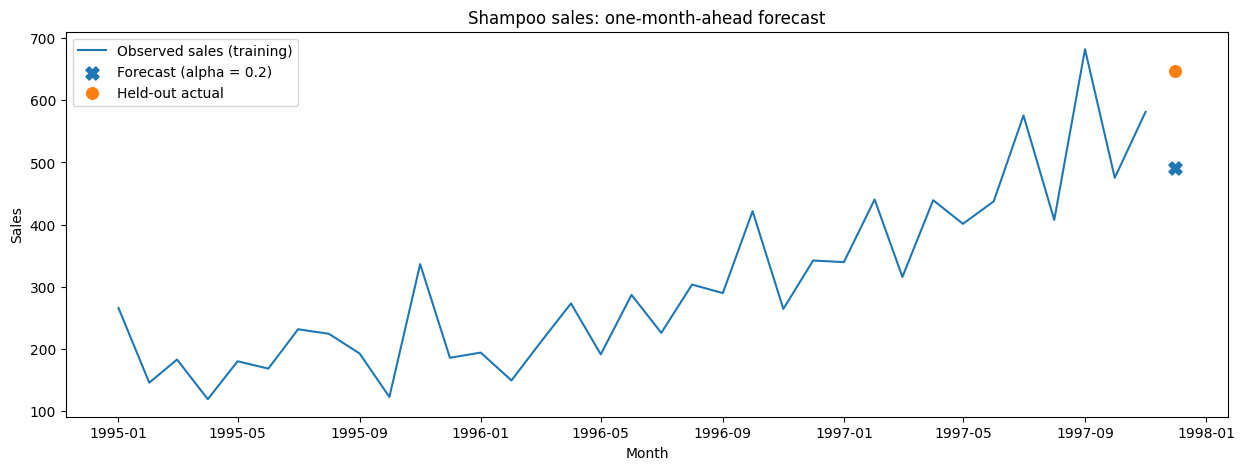

In [9]:
def simple_es(series, alpha):
    """Return the final smoothed level for a non-empty series."""
    if len(series) == 0:
        raise ValueError("series must contain at least one observation")
    if not 0 <= alpha <= 1:
        raise ValueError("alpha must be between 0 and 1")

    values = np.asarray(series)

    def level_at(t):
        if t == 0:
            return values[0]
        return alpha * values[t] + (1 - alpha) * level_at(t - 1)

    return level_at(len(values) - 1)


alpha = 0.2
training = df['Sales'].iloc[:-1]
forecast = simple_es(training, alpha)
last_month = df.index[-1]
actual = df['Sales'].iloc[-1]
print(f'{last_month:%B %Y}: forecast = {forecast:.2f}, actual = {actual:.2f}')

fig, ax = plt.subplots()
ax.plot(training.index, training, label='Observed sales (training)')
ax.scatter(last_month, forecast, marker='X', s=90, label=f'Forecast (alpha = {alpha})')
ax.scatter(last_month, actual, marker='o', s=70, label='Held-out actual')
ax.set(title='Shampoo sales: one-month-ahead forecast', xlabel='Month', ylabel='Sales')
ax.legend()
plt.show()

### Nonseasonal exponential smoothing with trend

Build a recursive function `double_es(series, alpha, beta)` that:
- return a trend using the trend update equation,
- use the `simple_es` function to calculate the level l(n) and l(n-1),
- use data[1] - data[0] as initial trend

Compute the forecasting on the last value.

In [10]:
def double_es(series, alpha, beta):
    """Return the final trend using simple-smoothed levels."""
    values = np.asarray(series)
    if len(values) < 2:
        raise ValueError("series must contain at least two observations")
    if not 0 <= beta <= 1:
        raise ValueError("beta must be between 0 and 1")

    levels = [simple_es(values[:end], alpha) for end in range(1, len(values) + 1)]

    def trend_at(t):
        if t == 0:
            return values[1] - values[0]
        level_change = levels[t] - levels[t - 1]
        return beta * level_change + (1 - beta) * trend_at(t - 1)

    return trend_at(len(values) - 1)


beta = 0.2
trend_forecast = simple_es(training, alpha) + double_es(training, alpha, beta)
print(f'{last_month:%B %Y}: forecast with trend = {trend_forecast:.2f}, actual = {actual:.2f}')

December 1997: forecast with trend = 510.32, actual = 646.90


Create a vector to see the estimation at each time step. Plot the graph. 

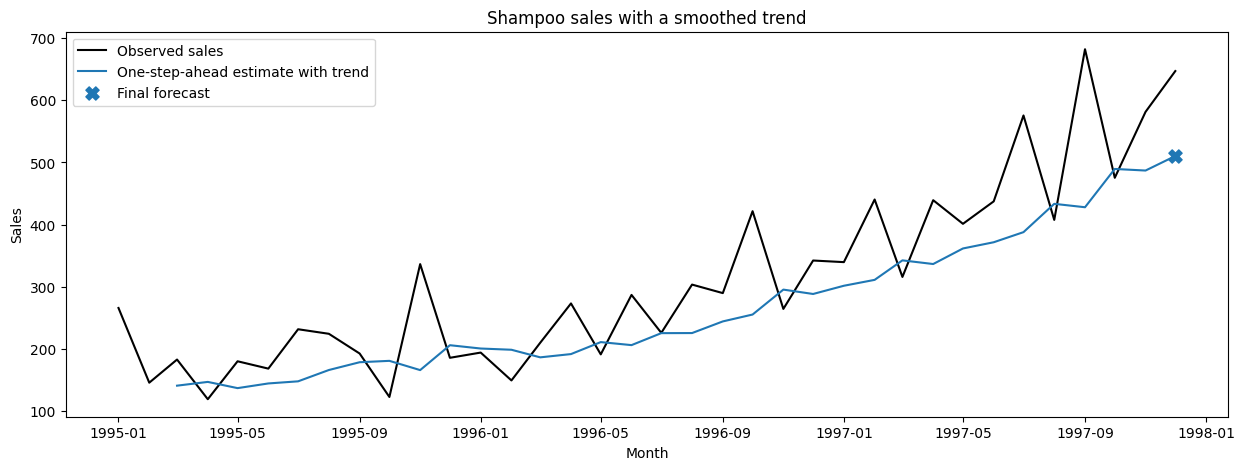

In [12]:
sales = df['Sales']
one_step_estimates = pd.Series(
    [simple_es(sales.iloc[:t], alpha) + double_es(sales.iloc[:t], alpha, beta)
     for t in range(2, len(sales))],
    index=sales.index[2:],
)

fig, ax = plt.subplots()
ax.plot(sales, label='Observed sales', color='black')
ax.plot(one_step_estimates, label='One-step-ahead estimate with trend')
ax.scatter(last_month, trend_forecast, marker='X', s=90, label='Final forecast')
ax.set(title='Shampoo sales with a smoothed trend', xlabel='Month', ylabel='Sales')
ax.legend()
plt.show()

## Exponential smoothing with built-in functions

In [13]:
from statsmodels.tsa.api import ExponentialSmoothing, SimpleExpSmoothing, Holt

### Simple exponential smoothing

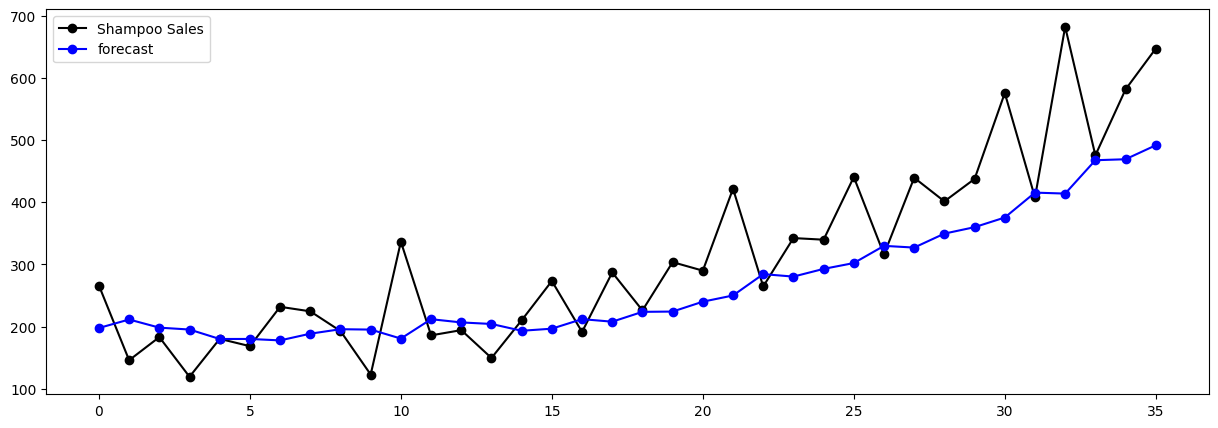

In [14]:
# Explicitly provide alpha to the model 
fit1 = SimpleExpSmoothing(data, initialization_method="heuristic").fit(
    smoothing_level=0.2, optimized=False)

plt.plot(data, marker="o", color="black", label='Shampoo Sales')
plt.plot(fit1.fittedvalues, marker="o", color="blue", label='forecast')
plt.legend()
plt.show()

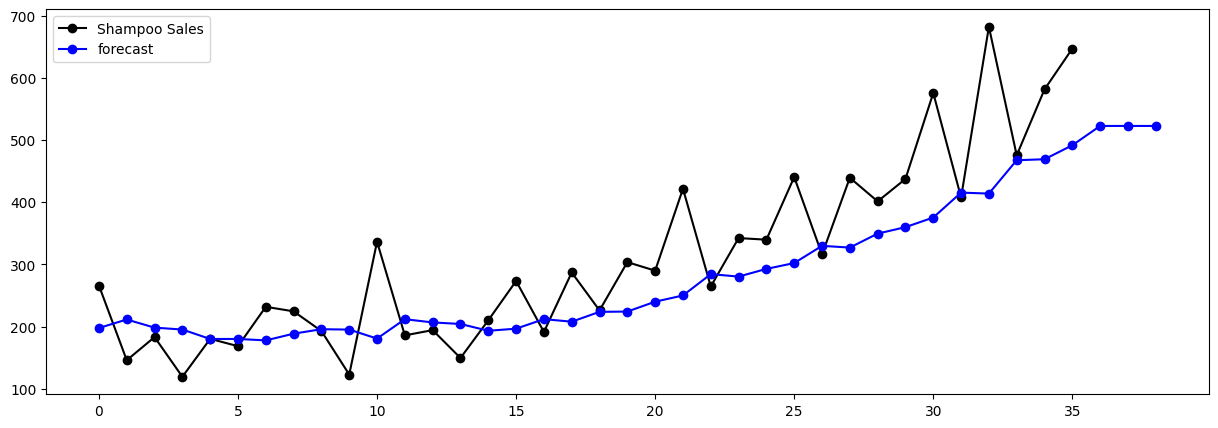

In [17]:
# Make forecasting 

forecast = fit1.forecast(3)
full_curve = np.concatenate((fit1.fittedvalues, forecast))

plt.plot(data, marker="o", color="black", label='Shampoo Sales')
plt.plot(full_curve, marker="o", color="blue", label='forecast')
plt.legend()
plt.show()

Use `statsmodel` to provide an optimized value for alpha.

In [18]:
optimized_ses = SimpleExpSmoothing(data, initialization_method="estimated").fit(
    optimized=True
)
optimized_alpha = optimized_ses.params["smoothing_level"]
print(f'Optimized alpha = {optimized_alpha:.4f}')

Optimized alpha = 0.3994


### Nonseasonal exponential smoothing with trend

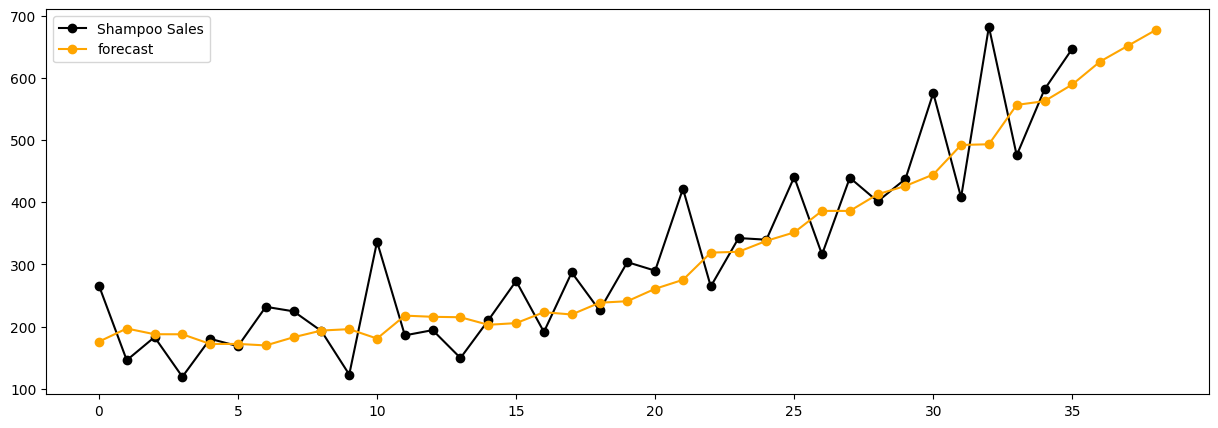

In [19]:
fit1 = Holt(data, initialization_method="estimated").fit(
    smoothing_level=0.2, smoothing_trend=0.2)

forecast = fit1.forecast(3)
full_curve = np.concatenate((fit1.fittedvalues, forecast))


plt.plot(data, marker="o", color="black", label='Shampoo Sales')
plt.plot(full_curve, marker="o", color="orange", label='forecast')
plt.legend()
plt.show()

### Holt’s Winters Seasonal

In [20]:
# The folowing data corresponds to the international visitor night in Australia (millions)

visitor_nights = [
    41.7275,
    24.0418,
    32.3281,
    37.3287,
    46.2132,
    29.3463,
    36.4829,
    42.9777,
    48.9015,
    31.1802,
    37.7179,
    40.4202,
    51.2069,
    31.8872,
    40.9783,
    43.7725,
    55.5586,
    33.8509,
    42.0764,
    45.6423,
    59.7668,
    35.1919,
    44.3197,
    47.9137,
]
index = pd.date_range(start="2005-01-01", periods=len(visitor_nights), freq="QS-JAN")
aust = pd.Series(visitor_nights, index=index, name="Visitor nights (millions)")

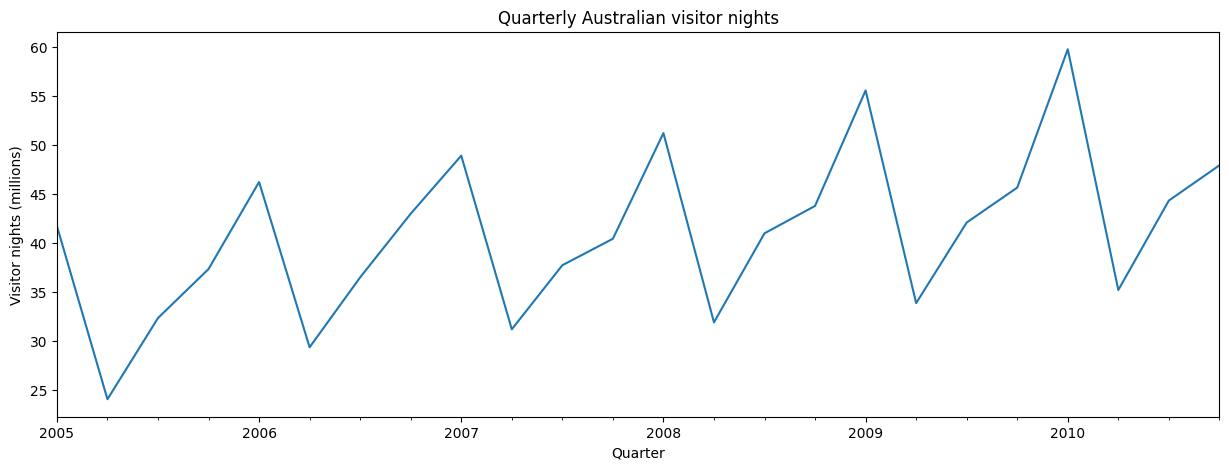

In [21]:
fig, ax = plt.subplots()
aust.plot(ax=ax)
ax.set(title='Quarterly Australian visitor nights', xlabel='Quarter',
       ylabel='Visitor nights (millions)')
plt.show()

How could you find the periodicity for this data? 

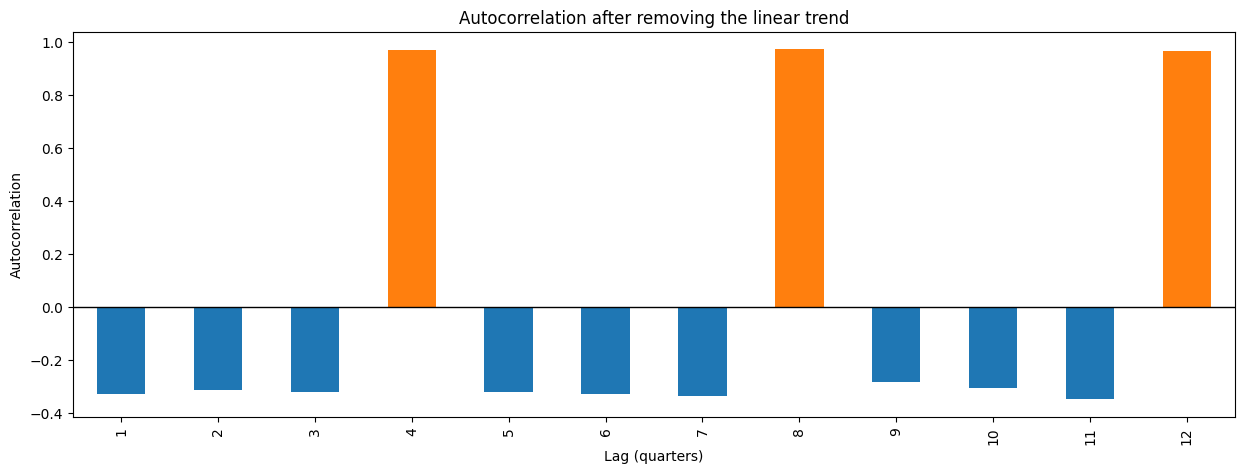

Lag-4 autocorrelation: 0.970
Peaks at lags 4, 8, and 12 indicate a repeating four-quarter cycle.


In [22]:
# Remove a linear trend before comparing values at different lags.
quarters = np.arange(len(aust))
slope, intercept = np.polyfit(quarters, aust, deg=1)
detrended = aust - (intercept + slope * quarters)
lags = range(1, 13)
autocorrelations = pd.Series([detrended.autocorr(lag) for lag in lags], index=lags)

ax = autocorrelations.plot(kind='bar', color=['tab:orange' if lag % 4 == 0 else 'tab:blue' for lag in lags])
ax.axhline(0, color='black', linewidth=1)
ax.set(title='Autocorrelation after removing the linear trend',
       xlabel='Lag (quarters)', ylabel='Autocorrelation')
plt.show()

print(f'Lag-4 autocorrelation: {autocorrelations.loc[4]:.3f}')
print('Peaks at lags 4, 8, and 12 indicate a repeating four-quarter cycle.')

The following cell fit a Holt’s Winters Seasonal model. What does mean these parameters?

In [ ]:
fit3 = ExponentialSmoothing(
    aust,
    seasonal_periods = 4,
    trend = "add",
    seasonal = "add",
    use_boxcox = False,
    initialization_method = "estimated",
).fit()

- `seasonal_periods=4` sets the cycle to four quarterly observations, or one year.
- `trend="add"` models trend as a change in the same units as the series.
- `seasonal="add"` adds a quarter-specific effect in millions of visitor nights.
- `use_boxcox=False` fits the model on the original scale.
- `initialization_method="estimated"` estimates the initial level, trend, and seasonal effects when fitting.

Forecast the time series for ten time steps. Plot the results.

In [ ]:
visitor_forecast = fit3.forecast(10)
print(visitor_forecast.round(2).to_string())

fig, ax = plt.subplots()
ax.plot(aust, marker='o', color='black', label='Observed')
ax.plot(fit3.fittedvalues, label='Fitted')
ax.plot(visitor_forecast, marker='o', linestyle='--', label='Forecast')
ax.set(title='Australian visitor nights: ten-quarter forecast',
       xlabel='Quarter', ylabel='Visitor nights (millions)')
ax.legend()
plt.show()